# SWaT anomaly detection + explanation: walkthrough

This notebook walks through the pipeline on the main setup (train on **SWaT.A11 + A10**, test on
**SWaT.A12**, AIT water-quality analysers excluded). The heavy experiments (all models x 3 seeds,
SWaT 2015, synthetic injection) are run by the scripts in `scripts/`; here we reuse their outputs
and train one GMM live to show the API.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from swatad import config as C, data as D
from swatad.pipeline import make_setup, valid_mask
from swatad.features import FeatureSpace
from swatad.rules import RuleMonitor
from swatad.models import GMMDet
from swatad.evaluate import smooth, full_report
pd.set_option('display.width', 200)

## 1. Data
A11 (normal, Feb 2026), A10 (normal, Dec 2023), A12 (11 attacks, Mar 2026). Bookkeeping columns start with `_`.

In [2]:
S = make_setup('a12', 'A11+A10')
print('train', S.train.shape, ' test', S.test.shape)
S.events[['event_id', 'name', 'targets', 'start', 'end']]

train (436977, 87)  test (28860, 87)


,event_id,name,targets,start,end
0,1,"Stage 5 valve manipulation: MV503/504 open, MV...",MV501-504,2026-03-11 13:24:50,2026-03-11 13:30:30
1,2,"Stage 1 flow disruption: MV101 open, P101 & P1...","MV101, P101, P102",2026-03-11 14:04:50,2026-03-11 14:10:30
2,3,Florida water plant scenario: dosing pump acti...,"P201-P206, MV201",2026-03-11 14:44:50,2026-03-11 14:50:30
3,4,Tank overflow via LIT101 spoofing (Schneider d...,LIT101,2026-03-11 14:54:50,2026-03-11 15:00:30
4,5,Stage 5 valve manipulation (repeat),MV501-504,2026-03-11 15:04:50,2026-03-11 15:10:30
5,6,Tank overflow via LIT101 spoofing (Schneider d...,LIT101,2026-03-11 15:24:50,2026-03-11 15:27:30
6,7,"Stage 2 parallel pump override: MV201 open, P1...","MV201, P101, P102",2026-03-11 15:25:00,2026-03-11 15:30:30
7,8,"RO backwash diversion: MV302 close, MV303 open","MV302, MV303",2026-03-11 15:44:50,2026-03-11 15:50:30
8,9,Forced backwash trigger via DPIT301 spoofing (...,DPIT301,2026-03-11 16:09:50,2026-03-11 16:15:30
9,10,Multi-value level oscillation: LIT601 spoofing...,LIT601,2026-03-11 16:34:50,2026-03-11 16:40:30


## 2. Features, rules and a GMM
The feature space is fit on valid normal rows only (no warm-up, no comms gaps). Rules are calibrated on A12 09:30-10:30, which disables drifted tags.

In [3]:
v = valid_mask(S.train)
fs = FeatureSpace(drop_ait=True).fit(S.train[v])
rules = RuleMonitor().fit(S.train[v]).calibrate(S.calib_df[S.calib_mask])
print(len(fs.cols), 'model features; rules disabled after calibration:', rules.disabled)
gmm = GMMDet().fit(fs.transform(S.train), v)
print('GMM components (BIC):', gmm.k)

32 model features; rules disabled after calibration: []


GMM components (BIC): 16


In [4]:
s, contrib = gmm.score(fs.transform(S.test))
s = smooth(s, 10)
thr = np.quantile(s[S.calib_mask], 0.995)
em = S.eval_mask
rep = full_report(s[em], S.test['_label'].values[em], thr, S.test.index[em], S.events)
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in rep.items()}

{'auc_roc': 0.869,
 'auc_pr': 0.724,
 'precision': 0.921,
 'recall': 0.512,
 'f1': 0.658,
 'fpr_normal': 0.007,
 'best_f1_oracle': 0.671,
 'event_recall': 0.636,
 'event_recall_overlap': 0.636,
 'events_detected': 7,
 'events_total': 11,
 'detected_ids': '1,2,3,4,5,8,9',
 'mean_delay_s': 138.714,
 'median_delay_s': 9.0,
 'alarm_events': 11,
 'false_alarm_events': 5,
 'event_precision': 0.545,
 'event_f1': 0.587}

Text(0.5, 1.0, 'A12, red = attacks')

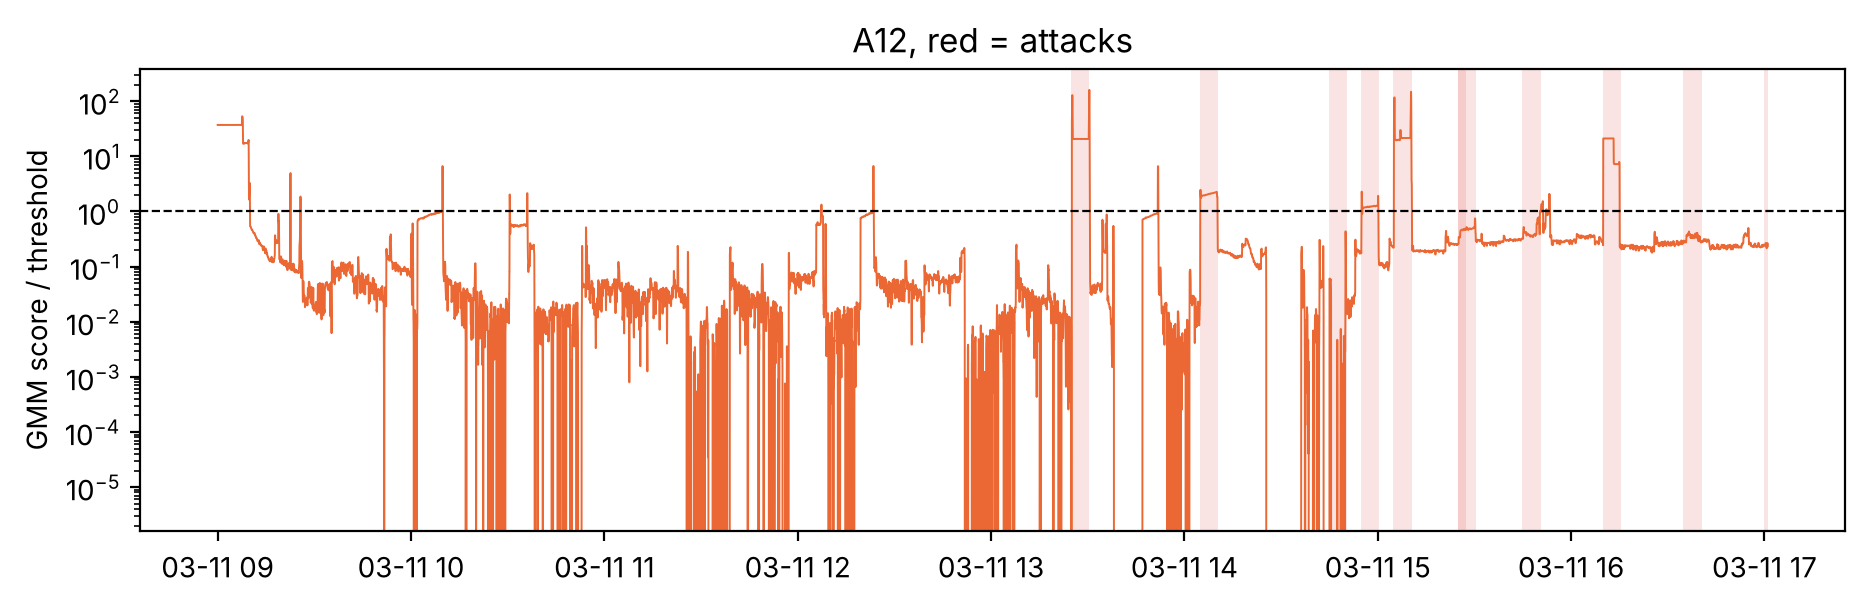

In [5]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.semilogy(S.test.index, s / thr, lw=0.7, color='#eb6834'); ax.axhline(1, color='k', ls='--', lw=0.8)
for _, a in S.events.iterrows(): ax.axvspan(a.start, a.end, color='#e34948', alpha=0.15, lw=0)
ax.set_ylabel('GMM score / threshold'); ax.set_title('A12, red = attacks')

## 3. Results of the full experiment grid (from `scripts/run_experiments.py`)

In [6]:
m = pd.read_csv(C.OUT_DIR / 'metrics_all.csv')
cols = ['auc_roc', 'auc_pr', 'f1', 'fpr_clean', 'event_recall', 'event_precision', 'mean_delay_s']
(m[m.variant.isin(['model', 'model+rules', 'rules'])]
   .groupby(['run', 'model', 'variant'])[cols].mean().round(3))

auc_roc  auc_pr     f1  fpr_clean  event_recall  event_precision  mean_delay_s
run                model      variant                                                                                    
a12_A11-A10_all    AE         model          0.895   0.705  0.603      0.007         0.939            0.525        78.321
                              model+rules    0.950   0.819  0.827      0.007         0.939            0.456        16.430
                   GMM        model          0.822   0.642  0.580      0.022         0.697            0.643       170.650
                              model+rules    0.897   0.779  0.790      0.022         0.970            0.727        24.685
                   IForest    model          0.754   0.286  0.090      0.020         0.394            0.472       318.050
...                                            ...     ...    ...        ...           ...              ...           ...
s2015_normal_noAIT LSTM-AE    model          0.908   0.811  0.665      0.000         0.524            0.125       309.470
                              model+rules    0.903   0.790  0.515      0.000         0.533            0.115       272.683
                   Rules only rules          0.531   0.131  0.179      0.000         0.457            0.206       309.125
                   WinAE      model          0.905   0.810  0.689      0.004         0.524            0.134       346.476
                              model+rules    0.901   0.787  0.525      0.004         0.514            0.119       291.426

[66 rows x 7 columns]

## 4. Per-anomaly JSON (detector -> explainer interface)

In [7]:
ev = json.load(open(C.OUT_DIR / 'anomalies' / 'a12_A11-A10_noAIT__WinAE.json'))
print(len(ev), 'events'); print(json.dumps(ev[1], indent=1)[:2500])

10 events
{
 "schema_version": "1.0",
 "event_id": "a12-WinAE-002",
 "dataset": "a12",
 "model": "WinAE",
 "detector_variant": "model+rules",
 "start": "2026-03-11 14:05:09",
 "end": "2026-03-11 14:12:00",
 "duration_s": 412,
 "peak_time": "2026-03-11 14:10:15",
 "threshold": 0.1853,
 "max_score": 0.3698,
 "mean_score": 0.2651,
 "max_score_ratio": 1.996,
 "triggered_by": "model+rules",
 "stages_involved": [
  "P1",
  "P2"
 ],
 "stage_names": {
  "P1": "raw water supply",
  "P2": "chemical dosing"
 },
 "top_contributors": [
  {
   "tag": "FIT201",
   "column": "FIT201.Pv",
   "stage": "P2",
   "kind": "sensor",
   "description": "Flow through chemical dosing section",
   "unit": "m3/h",
   "contribution": 88.651,
   "value_at_start": 0.0001,
   "value_min": 0.0,
   "value_max": 2.3584,
   "normal_p01": 0.0,
   "normal_median": 0.0,
   "normal_p99": 2.6857,
   "direction": "in-range",
   "signal": {
    "std_ratio": 0.813,
    "change": 2.3479,
    "slope_per_min": 0.4082,
    "direction

## 5. RAG explanation
Retrieval over `knowledge_base/` + template generation. With an API key, `Explainer(backend='claude')` sends the same retrieved context to Claude.

In [8]:
from swatad.rag.explainer import Explainer
E = Explainer(backend='template')
from IPython.display import Markdown
Markdown(E.explain(ev[1])['markdown'])

### a12-WinAE-002  (14:05:09 - 14:12:00)

Between 14:05:09 and 14:12:00 (412 s) the WinAE detector and the rule layer flagged an anomaly in P1 (raw water supply), P2 (chemical dosing); peak score 2.0x the threshold. Most likely interpretation: process variable outside its normal range.

**Evidence**
- FIT201 (Flow through chemical dosing section): 0 to 2.358 m3/h vs normal 0 to 2.686 -> in-range
- P101 (Raw water transfer pump (duty) P1->P2): values [1.0, 2.0] (normal [1.0, 2.0])
- FIT101 (Raw water inflow to T101): 0 to 3.893 m3/h vs normal 0 to 5.942 -> high
- Rule: LIT101 left its normal range [408.182, 911.064] (observed 911.292 to 960.436).

**Similar known attacks:** A12 attack 2: Stage 1 flow disruption: MV101 open, P101 & P102 stop; A12 attack 6: Tank overflow via LIT101 spoofing (Schneider demo attack 01)
**Matching pattern:** Sensor spoofing with an out-of-range constant value

**Relevant physical rules**
- When P101 is ON/open (2), FIT201 is normally between 2.34 and 2.39; when P101 is OFF/closed (1), FIT201 is between 0 and 0 (effect size 12.9).
- When MV101 is ON/open (2), FIT101 is normally between 2.56 and 2.58; when MV101 is OFF/closed (1), FIT101 is between 0 and 0 (effect size 27.5).

**Recommended checks**
- Check whether a real process excursion is happening (overflow, pressure).
- Check the actuators that control this variable.

Confidence: medium. Sources: 02_tag_dictionary#8, 02_tag_dictionary#5, 02_tag_dictionary#3, 02_tag_dictionary#2, 03_attack_and_fault_patterns#1, 04_a12_attack_catalog#2, 04_a12_attack_catalog#6, 05_mined_invariants#7, 05_mined_invariants#1, 01_process_overview#2
_Ground truth (evaluation only, not given to the explainer): #2 Stage 1 flow disruption: MV101 open, P101 & P102 stop_


In [9]:
pd.read_csv(C.OUT_DIR / 'explanations' / 'a12_A11-A10_noAIT__WinAE_eval.csv')

,attack_id,event_id,targets,top3_contributors,new_rule_tags,target_in_top3,target_in_top3_or_rules,predicted_category,true_category,category_correct,known_attack_top2,known_attack_correct,loo_top1_same_category
0,1,a12-WinAE-001,MV501-504,"MV501,LSLL203,LIT602",P501,True,True,actuator_manipulation,actuator_manipulation,True,A12 attack 5: Stage 5 valve manipulation (repe...,True,True
1,2,a12-WinAE-002,"MV101, P101, P102","FIT201,P101,FIT101",LIT101,True,True,out_of_range_excursion,actuator_manipulation,False,A12 attack 2: Stage 1 flow disruption: MV101 o...,True,False
2,3,a12-WinAE-004,"P201-P206, MV201","LSH601,P205,LIT601","P202,P204,P206",True,True,standby_activation,standby_activation,True,A12 attack 3: Florida water plant scenario: do...,True,False
3,4,a12-WinAE-005,LIT101,"LIT101,LIT301,FIT101",LIT101,True,True,spoof_out_of_range,spoof_out_of_range,True,A12 attack 4: Tank overflow via LIT101 spoofin...,True,True
4,5,a12-WinAE-006,MV501-504,"MV501,FIT504,LSLL203","P501,FIT504",True,True,spoof_out_of_range,actuator_manipulation,False,A12 attack 4: Tank overflow via LIT101 spoofin...,False,False
5,6,a12-WinAE-007,LIT101,"LIT301,P205,LIT401",P102,False,False,standby_activation,drift_or_inrange,False,A12 attack 7: Stage 2 parallel pump override: ...,False,False
6,7,a12-WinAE-007,"MV201, P101, P102","LIT301,P205,LIT401",P102,False,True,standby_activation,standby_activation,True,A12 attack 7: Stage 2 parallel pump override: ...,True,True
7,8,a12-WinAE-008,"MV302, MV303","DPIT301,P301,FIT301","P3_STATE,MV301,MV303,P602,DPIT301,FIT601",False,True,standby_activation,standby_activation,True,A12 attack 8: RO backwash diversion: MV302 clo...,True,False
8,9,a12-WinAE-009,DPIT301,"DPIT301,FIT301,P301",DPIT301,True,True,spoof_out_of_range,spoof_out_of_range,True,A12 attack 9: Forced backwash trigger via DPIT...,True,True
9,10,a12-WinAE-010,LIT601,"LIT601,MV201,FIT201",LIT601,True,True,oscillation,oscillation,True,A12 attack 10: Multi-value level oscillation: ...,True,False


## 6. Synthetic injections (from `scripts/run_synthetic.py`)

In [10]:
s = pd.read_csv(C.OUT_DIR / 'synthetic' / 'synthetic_summary.csv')
s[s.variant == 'model'].pivot(index='type', columns='model', values='recall').round(2)

model,AE,GMM,IForest,LSTM-AE,WinAE
type,,,,,
ALL,0.72,0.52,0.12,0.55,0.62
actuator_flip,0.83,0.50,0.00,0.33,0.67
bias,0.67,0.50,0.00,1.00,1.00
drift,1.00,0.67,0.17,0.83,0.83
noise,1.00,0.67,0.17,1.00,1.00
replay,0.50,0.50,0.00,0.25,0.00
spike,1.00,0.83,0.17,0.33,0.67
stuck,0.00,0.00,0.33,0.00,0.00
